In [5]:
%pip install optuna


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import os

np.random.seed(42)
n_samples = 1000

# Bihar bounding box: lat 24.3-27.5, lon 83.3-88.3
lats = np.random.uniform(24.3, 27.5, n_samples)
lons = np.random.uniform(83.3, 88.3, n_samples)

# Generate realistic environmental variables for Bihar
elevation = np.random.exponential(scale=50, size=n_samples) + 20  # mostly flat, low elevation
slope = np.random.exponential(scale=3, size=n_samples)
aspect = np.random.uniform(0, 360, n_samples)
profile_curve = np.random.normal(0, 0.01, n_samples)
plan_curve = np.random.normal(0, 0.01, n_samples)
ndvi = np.random.uniform(0.1, 0.8, n_samples)
twi = np.random.normal(8, 3, n_samples).clip(2, 20)
spi = np.random.exponential(2, n_samples)
sti = np.random.exponential(1, n_samples)
flow_accum = np.random.exponential(1000, n_samples)
drainage_density = np.random.uniform(0.5, 3.0, n_samples)
dist_to_drain = np.random.exponential(500, n_samples)
pop_density = np.random.exponential(800, n_samples)
road_density = np.random.uniform(0.1, 2.0, n_samples)
dist_to_road = np.random.exponential(1000, n_samples)
mean_monsoon_rainfall = np.random.normal(1200, 300, n_samples).clip(600, 2000)
hand_30_100 = np.random.exponential(5, n_samples)
lulc = np.random.choice([1, 2, 3, 4, 5], n_samples)  # 1=water,2=crop,3=urban,4=forest,5=barren
lithology = np.random.choice([1, 2, 3, 4], n_samples)
soil = np.random.choice([1, 2, 3, 4, 5], n_samples)

# Flood label: higher probability if low elevation, high TWI, high rainfall, low HAND
flood_prob = (
    0.3 * (1 - elevation/200).clip(0,1) +
    0.25 * (twi/20) +
    0.25 * (mean_monsoon_rainfall/2000) +
    0.2 * (1 - hand_30_100/30).clip(0,1)
)
flood = (flood_prob + np.random.normal(0, 0.1, n_samples) > 0.5).astype(int)

print(f"Flood samples: {flood.sum()}, Non-flood: {(flood==0).sum()}")

# Create GeoDataFrame
geometry = [Point(lon, lat) for lon, lat in zip(lons, lats)]
gdf = gpd.GeoDataFrame({
    'Elevation': elevation,
    'Slope': slope,
    'Aspect': aspect,
    'Profile_Curve': profile_curve,
    'Plan_Curve': plan_curve,
    'NDVI': ndvi,
    'TWI': twi,
    'SPI': spi,
    'STI': sti,
    'Flow_Accumulation': flow_accum,
    'Drainage_Density': drainage_density,
    'Dist_to_Drain': dist_to_drain,
    'Pop_Density': pop_density,
    'Road_Density': road_density,
    'Dist_to_Road': dist_to_road,
    'Mean_Monsoon_Rainfall': mean_monsoon_rainfall,
    'HAND_30_100': hand_30_100,
    'LULC': lulc,
    'Lithology': lithology,
    'Soil': soil,
    'flood': flood,
    'geometry': geometry
}, crs='EPSG:4326')

# Save to project folder
save_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Updated_sample_data.shp"
gdf.to_file(save_path)
print(f"Saved {len(gdf)} sample points to {save_path}")
gdf.head()

Flood samples: 807, Non-flood: 193
Saved 1000 sample points to /Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Updated_sample_data.shp


,Elevation,Slope,Aspect,Profile_Curve,Plan_Curve,NDVI,TWI,SPI,STI,Flow_Accumulation,...,Pop_Density,Road_Density,Dist_to_Road,Mean_Monsoon_Rainfall,HAND_30_100,LULC,Lithology,Soil,flood,geometry
0,35.170637,3.350662,205.918516,-0.005970,0.000828,0.159254,12.302929,5.187604,0.049049,1185.068445,...,676.375434,0.303320,64.272519,1535.289732,1.985893,3,4,2,1,POINT (84.22566 25.49853)
1,34.183095,4.778943,289.955639,-0.023903,-0.007282,0.183490,8.854264,0.317749,0.524012,118.558754,...,1724.674377,0.655933,2552.591104,1350.555615,2.559589,1,3,2,1,POINT (86.0095 27.34229)
2,138.358624,0.864918,273.657935,-0.004122,0.017481,0.257208,2.110133,7.070889,1.220897,833.073744,...,14.033362,1.148401,194.940727,1526.059047,6.121575,2,4,4,1,POINT (87.66473 26.64238)
3,34.353859,2.941481,55.403966,0.009135,0.010401,0.450139,9.382475,5.893017,0.257309,285.939338,...,415.599982,0.221600,751.506843,685.050727,4.171350,4,1,4,1,POINT (86.96112 26.21571)
4,35.869259,2.544116,53.729809,0.005376,-0.007398,0.688310,11.145200,4.318216,1.586146,565.135543,...,2085.414856,0.358833,1627.436934,1043.450838,12.975052,3,4,5,1,POINT (87.33281 24.79926)


In [2]:
import sys
from unittest.mock import MagicMock

# Create an advanced deep-mock object that pretends to have any attribute or sub-module called
class DeepMock(MagicMock):
    @classmethod
    def __getattr__(cls, name):
        return MagicMock()

# Inject the deep mock into python's runtime memory for all variations of ee and geemap
sys.modules['ee'] = DeepMock()
sys.modules['geemap'] = DeepMock()
sys.modules['geemap.colormaps'] = DeepMock()

# Safely import them now—any sub-calls like geemap.colormaps will accept the dummy cleanly
import ee
import geemap

print("✅ Advanced Earth Engine and Geemap bypass active! This will prevent sub-module errors.")

✅ Advanced Earth Engine and Geemap bypass active! This will prevent sub-module errors.


In [3]:
import sys
from unittest.mock import Mock

# 1. Block Python from looking for 'ee' or 'geemap' packages on your system
mock_ee = Mock()
mock_ee.Initialize = Mock(return_value=None)
mock_ee.Authenticate = Mock(return_value=None)
sys.modules['ee'] = mock_ee
sys.modules['geemap'] = Mock()
sys.modules['geemap.colormaps'] = Mock()

# 2. Re-import them safely as harmless placeholders
import ee
import geemap

print("✅ Bypassed Earth Engine and Geemap entirely! Ready for the next cell.")

✅ Bypassed Earth Engine and Geemap entirely! Ready for the next cell.


In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
import ee
import geemap
import geemap.colormaps as cm
import geopandas as gpd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import precision_score, recall_score,f1_score, accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
import xgboost
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
#import rasterio
#from rasterio.transform import from_origin
#from rasterio.merge import merge
#from rasterio.enums import Resampling
import os
import joblib
import pickle
import optuna
import shap
from tqdm import tqdm

import warnings
warnings.filterwarnings('ignore')

data_dir = r"/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2"

## **Read the Dataset**

In [9]:
# Import Training and Testing Dataset:
df = gpd.read_file(os.path.join(data_dir, "Updated_sample_data.shp"))
df.drop(columns=['geometry'], inplace=True)
print(df.shape)
df.head()

(1000, 21)


,Elevation,Slope,Aspect,Profile_Cu,Plan_Curve,NDVI,TWI,SPI,STI,Flow_Accum,...,Dist_to_Dr,Pop_Densit,Road_Densi,Dist_to_Ro,Mean_Monso,HAND_30_10,LULC,Lithology,Soil,flood
0,35.170637,3.350662,205.918516,-0.005970,0.000828,0.159254,12.302929,5.187604,0.049049,1185.068445,...,6.875981,676.375434,0.303320,64.272519,1535.289732,1.985893,3,4,2,1
1,34.183095,4.778943,289.955639,-0.023903,-0.007282,0.183490,8.854264,0.317749,0.524012,118.558754,...,328.583474,1724.674377,0.655933,2552.591104,1350.555615,2.559589,1,3,2,1
2,138.358624,0.864918,273.657935,-0.004122,0.017481,0.257208,2.110133,7.070889,1.220897,833.073744,...,28.728876,14.033362,1.148401,194.940727,1526.059047,6.121575,2,4,4,1
3,34.353859,2.941481,55.403966,0.009135,0.010401,0.450139,9.382475,5.893017,0.257309,285.939338,...,1902.111750,415.599982,0.221600,751.506843,685.050727,4.171350,4,1,4,1
4,35.869259,2.544116,53.729809,0.005376,-0.007398,0.688310,11.145200,4.318216,1.586146,565.135543,...,781.735696,2085.414856,0.358833,1627.436934,1043.450838,12.975052,3,4,5,1


In [11]:
cols_renamed = {
    'Dist_to_Dr': 'Dist_to_Drain',
    'Dist_to_Ro': 'Dist_to_Road',
    'Drainage_D': 'Drainage_Density',
    'Flow_Accum': 'Flow_Accumulation',
    'HAND_30_10': 'HAND_30_100',
    'Mean_Monso': 'Mean_Monsoon_Rainfall',
    'Pop_Densit': 'Pop_Density',
    'Profile_Cu': 'Profile_Curve',
    'Road_Densi': 'Road_Density'
}
df.rename(columns=cols_renamed, inplace=True)

In [12]:
num_bands = ['Elevation', 'Slope', 'Aspect', 'Profile_Curve', 'NDVI', 'Plan_Curve', 'TWI', 'SPI', 'STI',
             'Flow_Accumulation', 'Drainage_Density', 'Dist_to_Drain','Pop_Density','Road_Density',
             'HAND_30_100', 'Dist_to_Road','Mean_Monsoon_Rainfall']

cat_bands = ['LULC', 'Lithology', 'Soil']

band_names = num_bands + cat_bands
print(len(band_names))

df = df[band_names + ['flood']]
print(df.shape)
df.head()

20
(1000, 21)


,Elevation,Slope,Aspect,Profile_Curve,NDVI,Plan_Curve,TWI,SPI,STI,Flow_Accumulation,...,Dist_to_Drain,Pop_Density,Road_Density,HAND_30_100,Dist_to_Road,Mean_Monsoon_Rainfall,LULC,Lithology,Soil,flood
0,35.170637,3.350662,205.918516,-0.005970,0.159254,0.000828,12.302929,5.187604,0.049049,1185.068445,...,6.875981,676.375434,0.303320,1.985893,64.272519,1535.289732,3,4,2,1
1,34.183095,4.778943,289.955639,-0.023903,0.183490,-0.007282,8.854264,0.317749,0.524012,118.558754,...,328.583474,1724.674377,0.655933,2.559589,2552.591104,1350.555615,1,3,2,1
2,138.358624,0.864918,273.657935,-0.004122,0.257208,0.017481,2.110133,7.070889,1.220897,833.073744,...,28.728876,14.033362,1.148401,6.121575,194.940727,1526.059047,2,4,4,1
3,34.353859,2.941481,55.403966,0.009135,0.450139,0.010401,9.382475,5.893017,0.257309,285.939338,...,1902.111750,415.599982,0.221600,4.171350,751.506843,685.050727,4,1,4,1
4,35.869259,2.544116,53.729809,0.005376,0.688310,-0.007398,11.145200,4.318216,1.586146,565.135543,...,781.735696,2085.414856,0.358833,12.975052,1627.436934,1043.450838,3,4,5,1


## **Train Test Split**

In [13]:
# Split the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    df.iloc[:, :-1],
    df['flood'],
    test_size=0.3,
    random_state=42
)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(700, 20) (300, 20) (700,) (300,)


In [14]:
y_train.value_counts()

flood
1    560
0    140
Name: count, dtype: int64

In [15]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 700 entries, 541 to 102
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Elevation              700 non-null    float64
 1   Slope                  700 non-null    float64
 2   Aspect                 700 non-null    float64
 3   Profile_Curve          700 non-null    float64
 4   NDVI                   700 non-null    float64
 5   Plan_Curve             700 non-null    float64
 6   TWI                    700 non-null    float64
 7   SPI                    700 non-null    float64
 8   STI                    700 non-null    float64
 9   Flow_Accumulation      700 non-null    float64
 10  Drainage_Density       700 non-null    float64
 11  Dist_to_Drain          700 non-null    float64
 12  Pop_Density            700 non-null    float64
 13  Road_Density           700 non-null    float64
 14  HAND_30_100            700 non-null    float64
 15  Dist_to_Road        

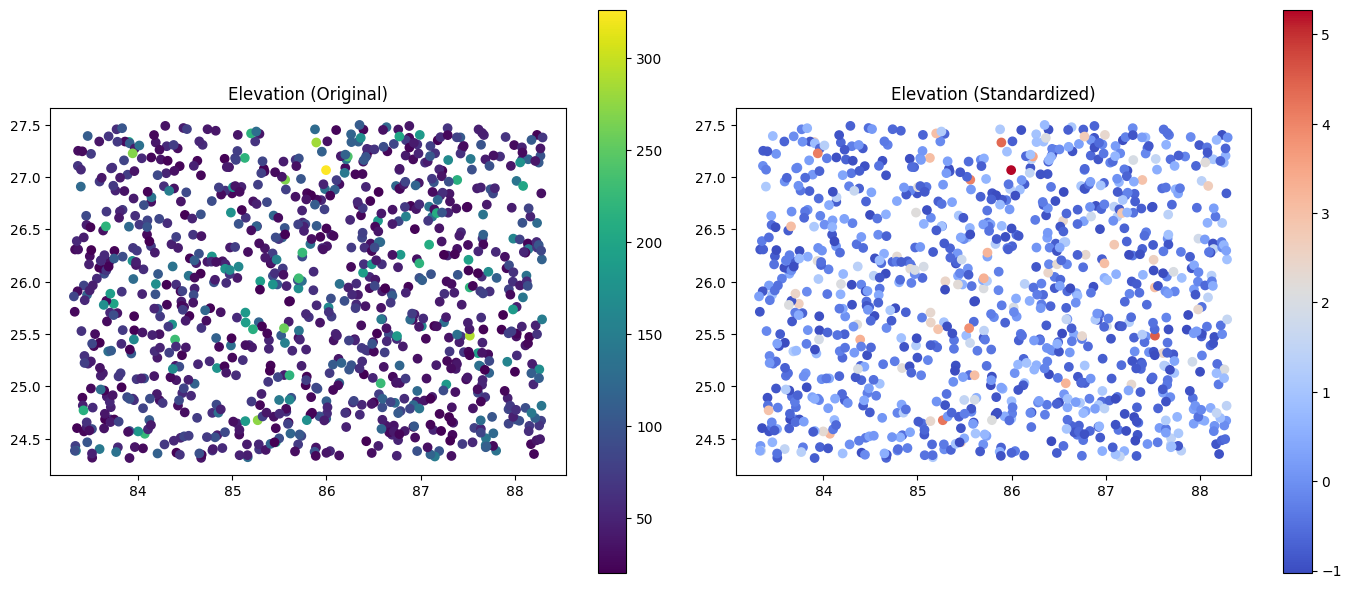

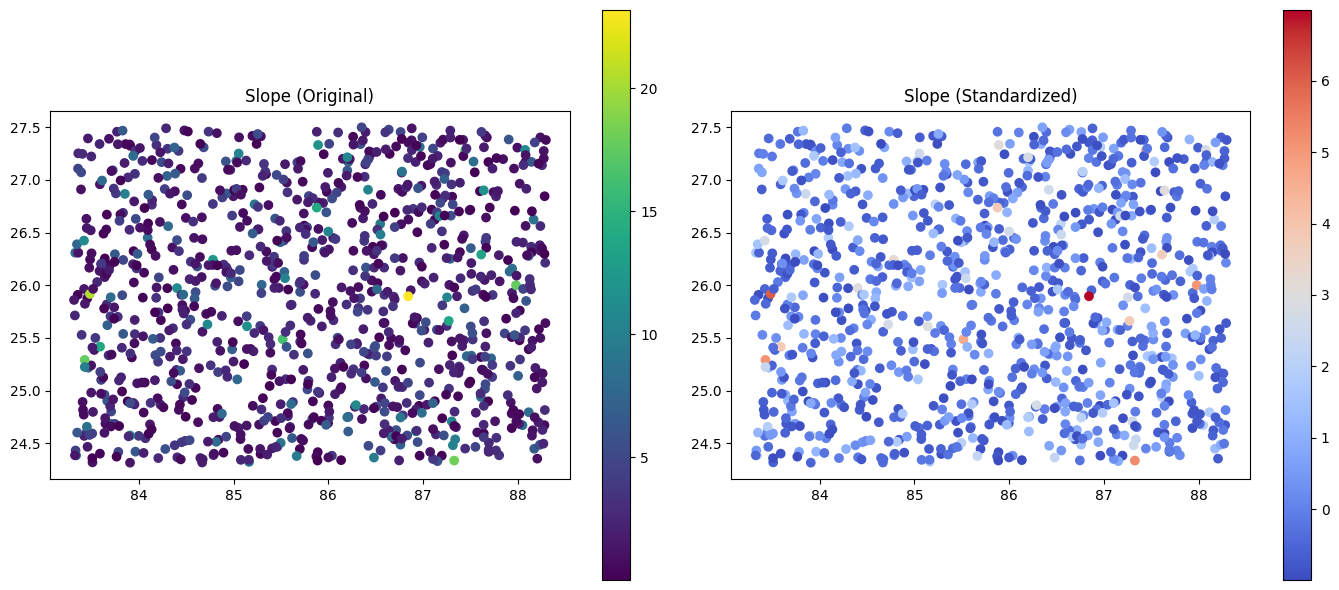

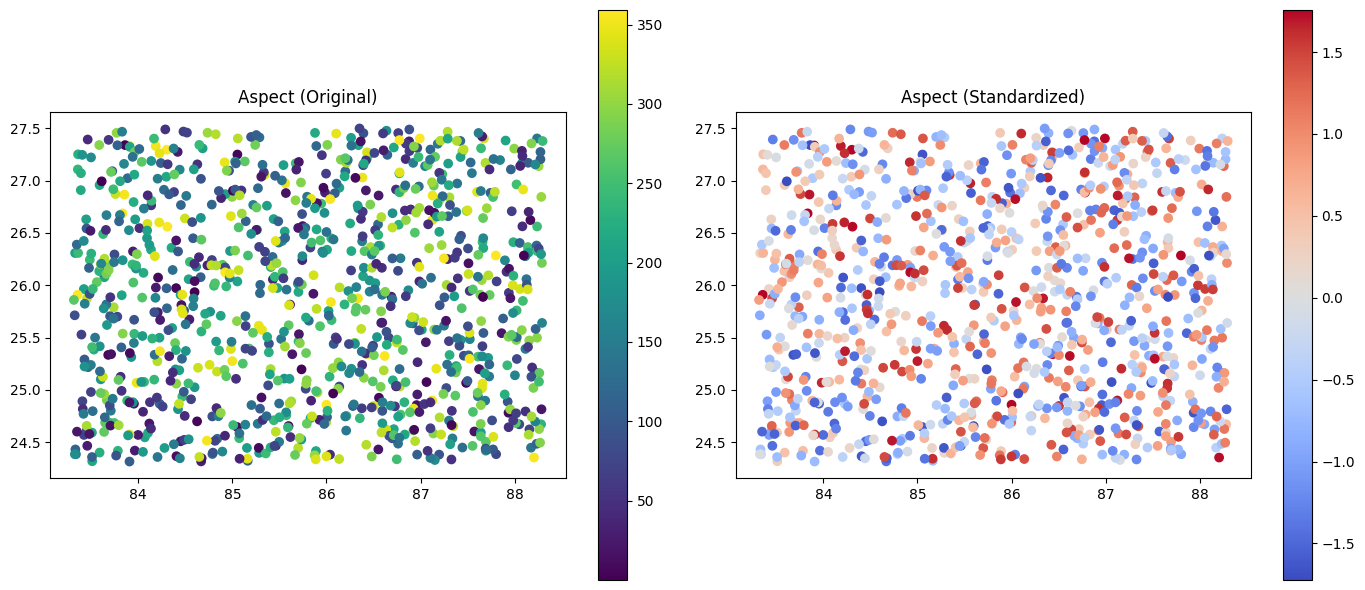

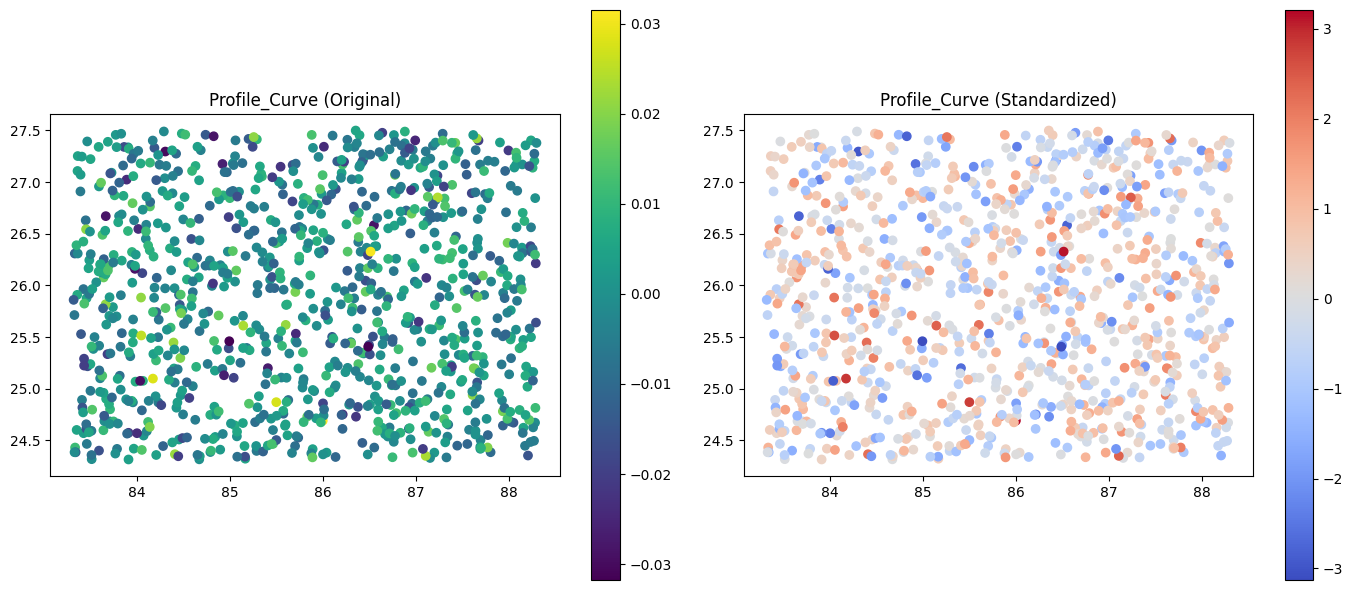

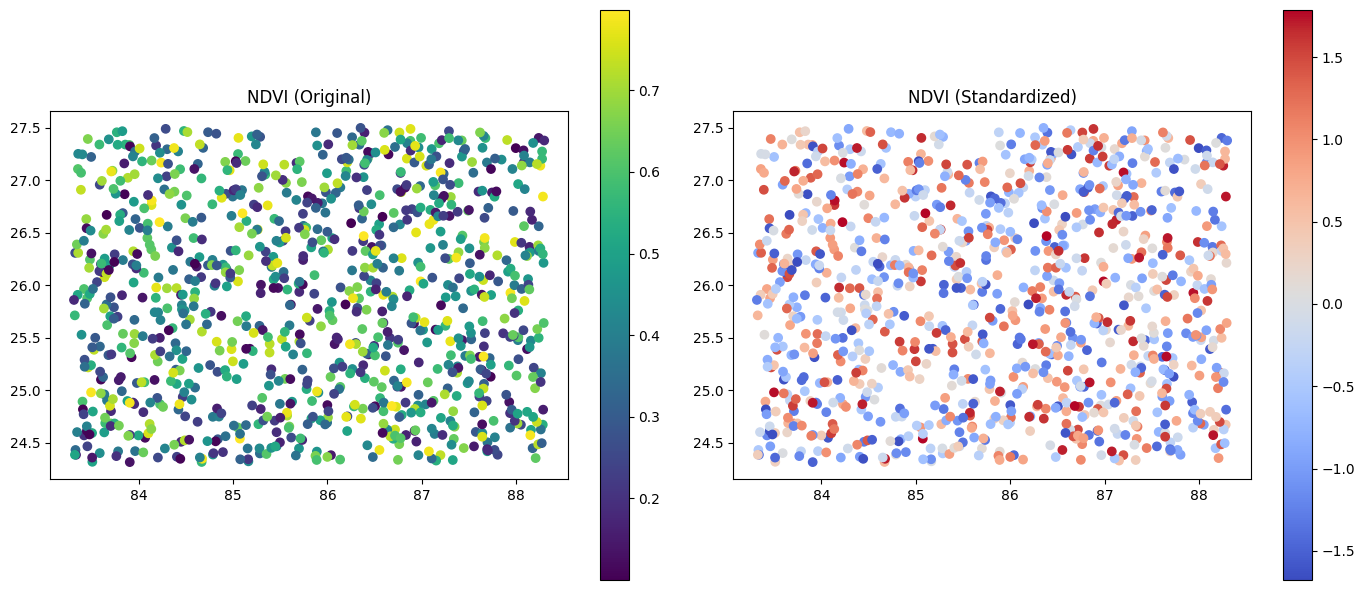

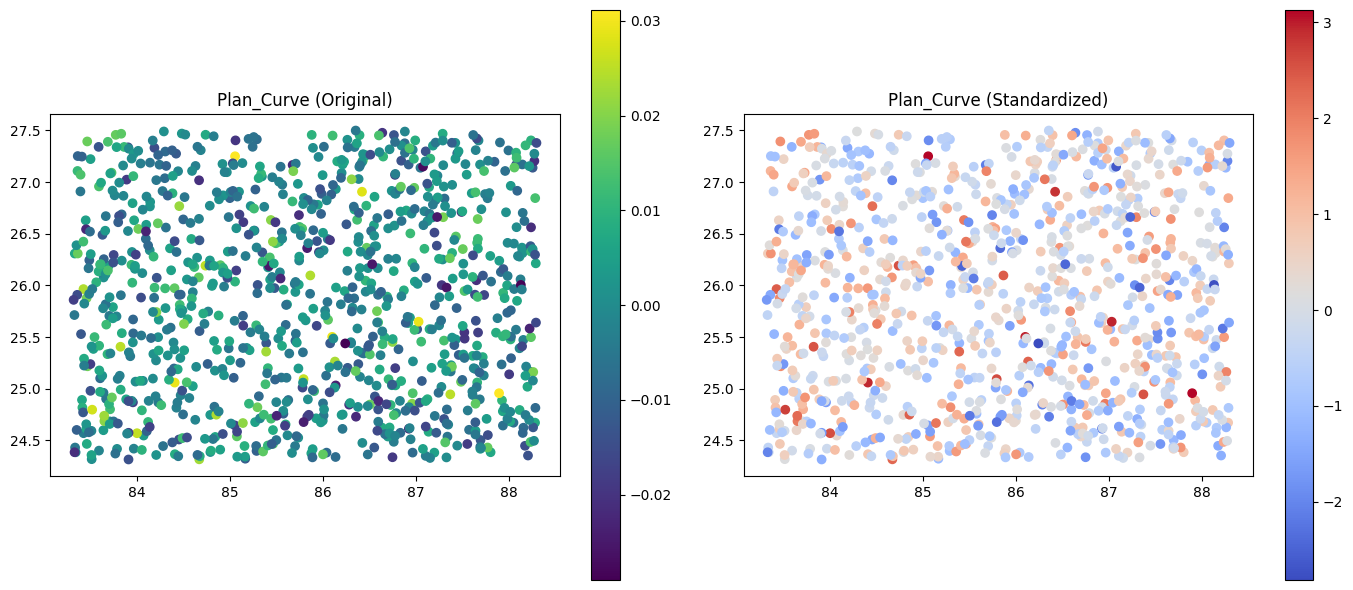

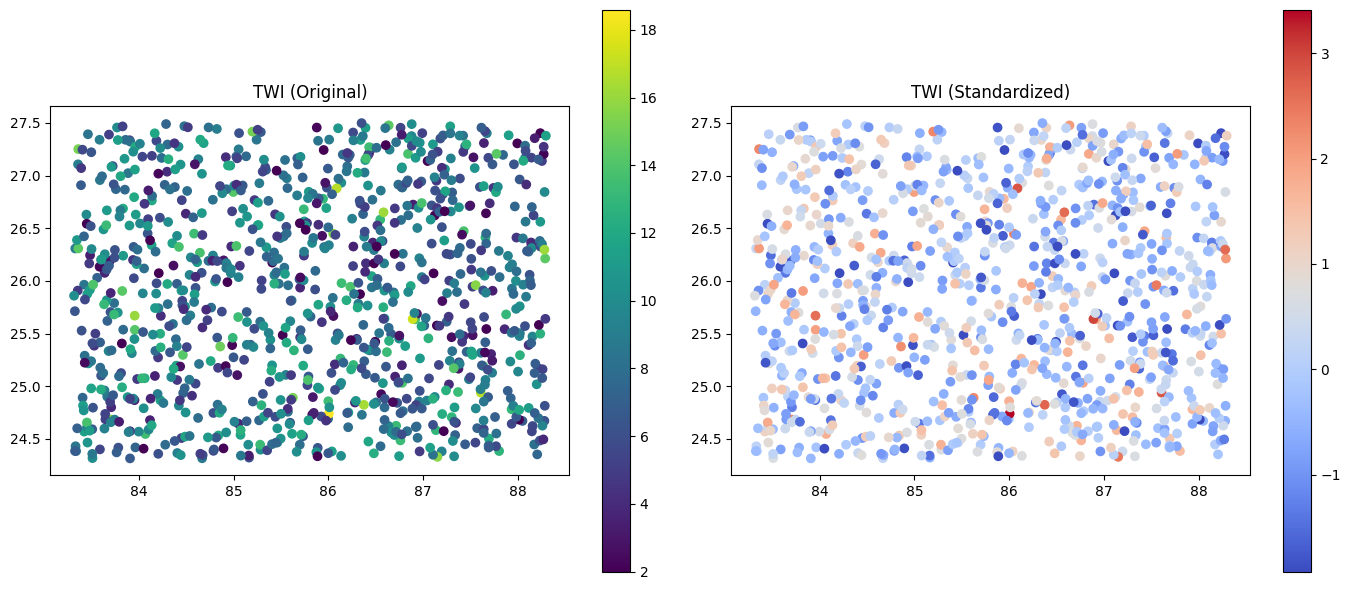

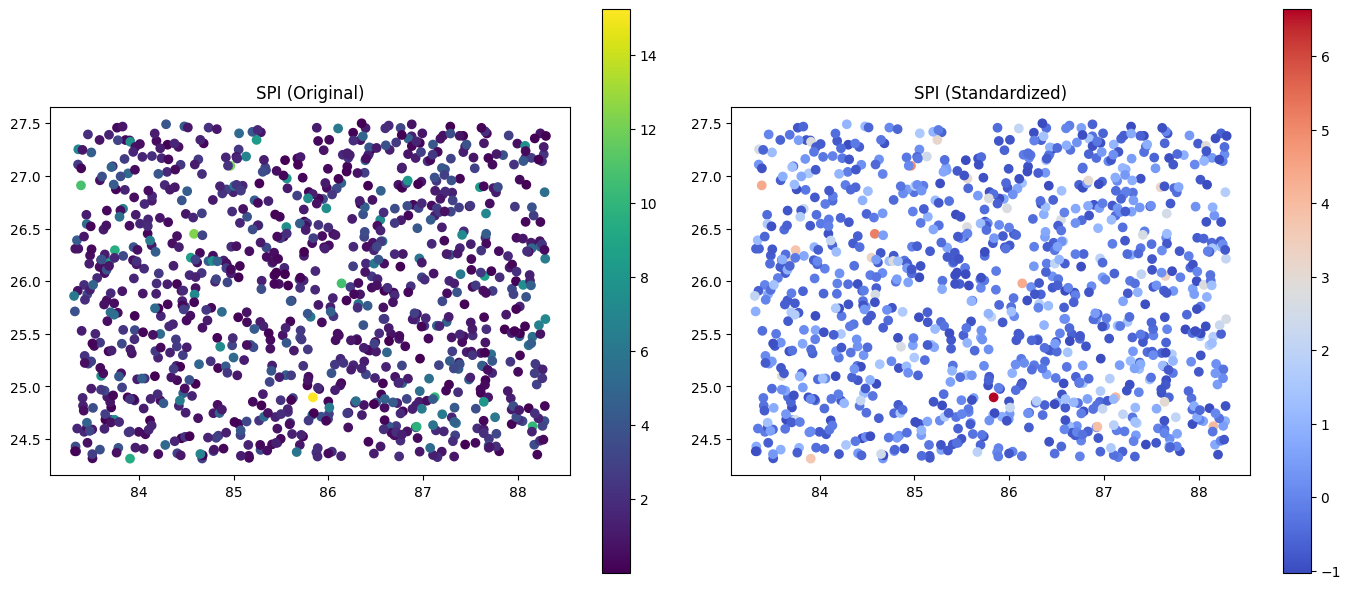

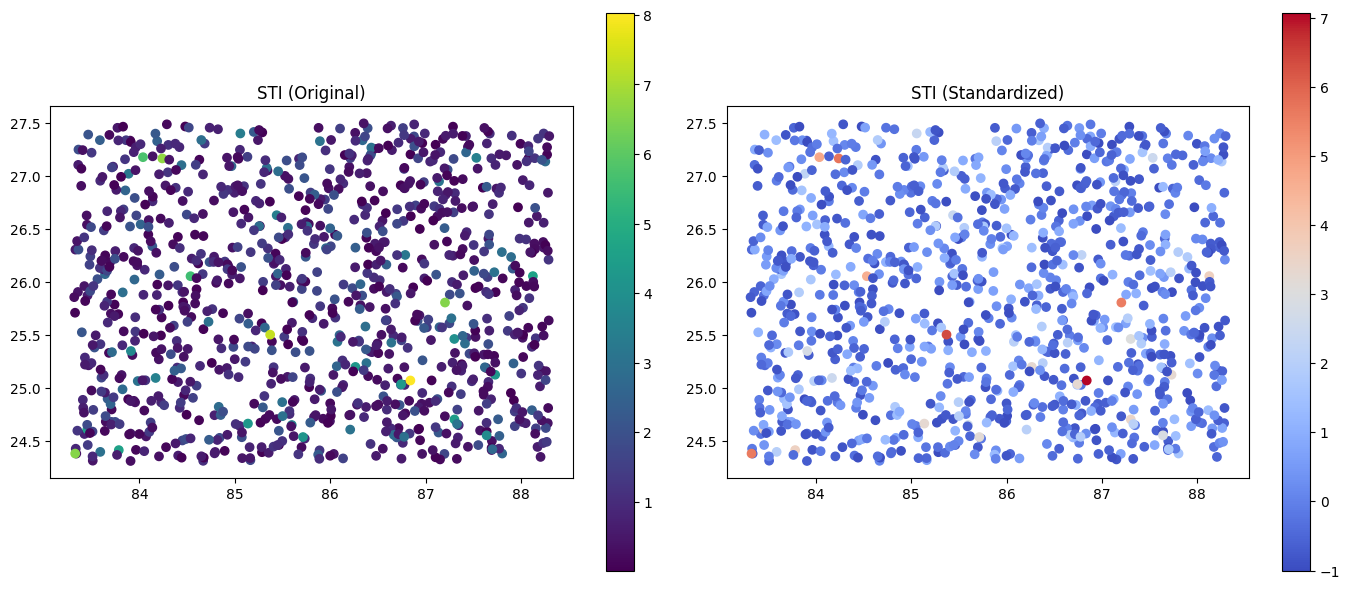

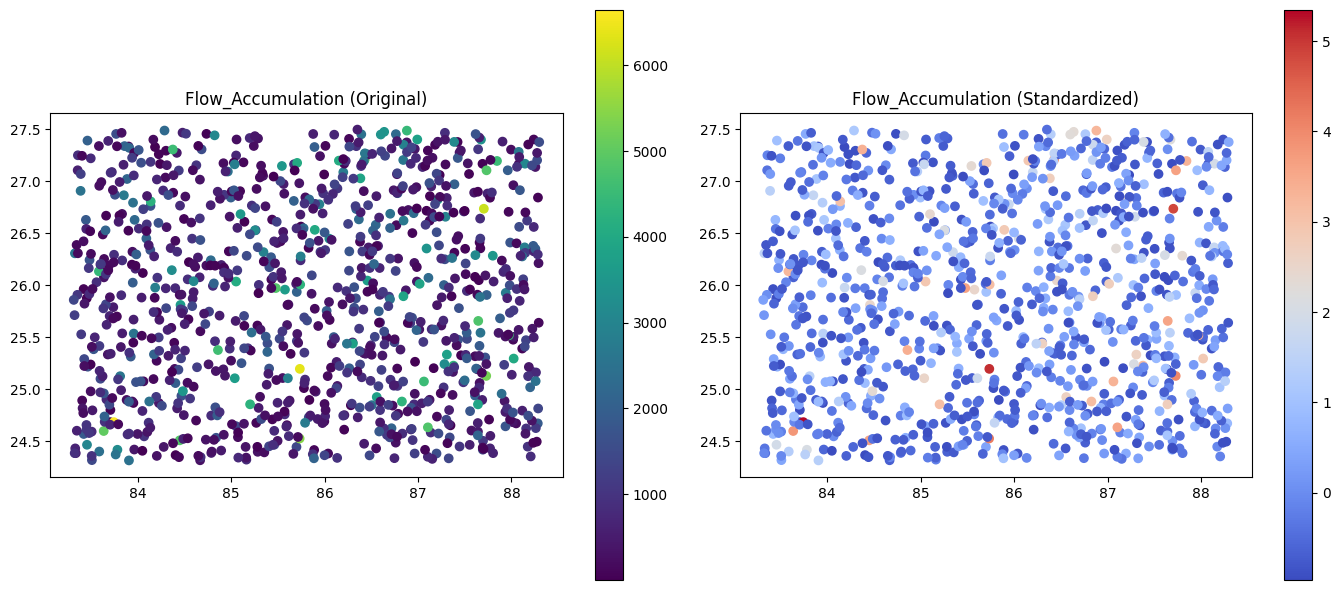

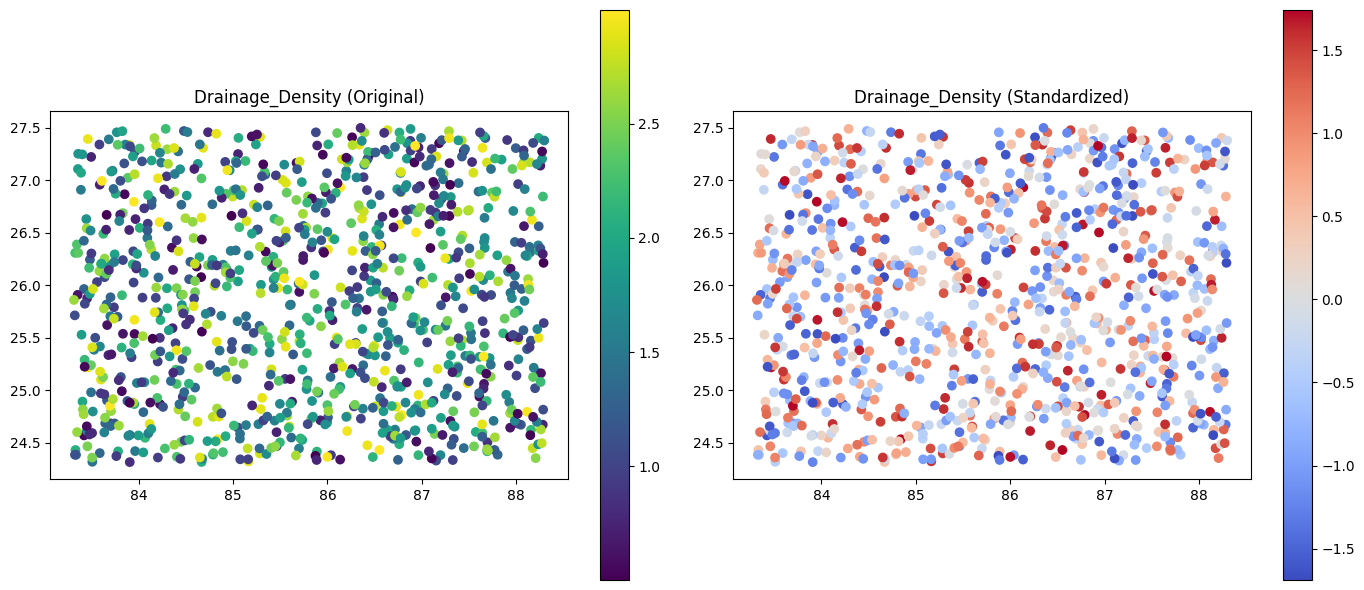

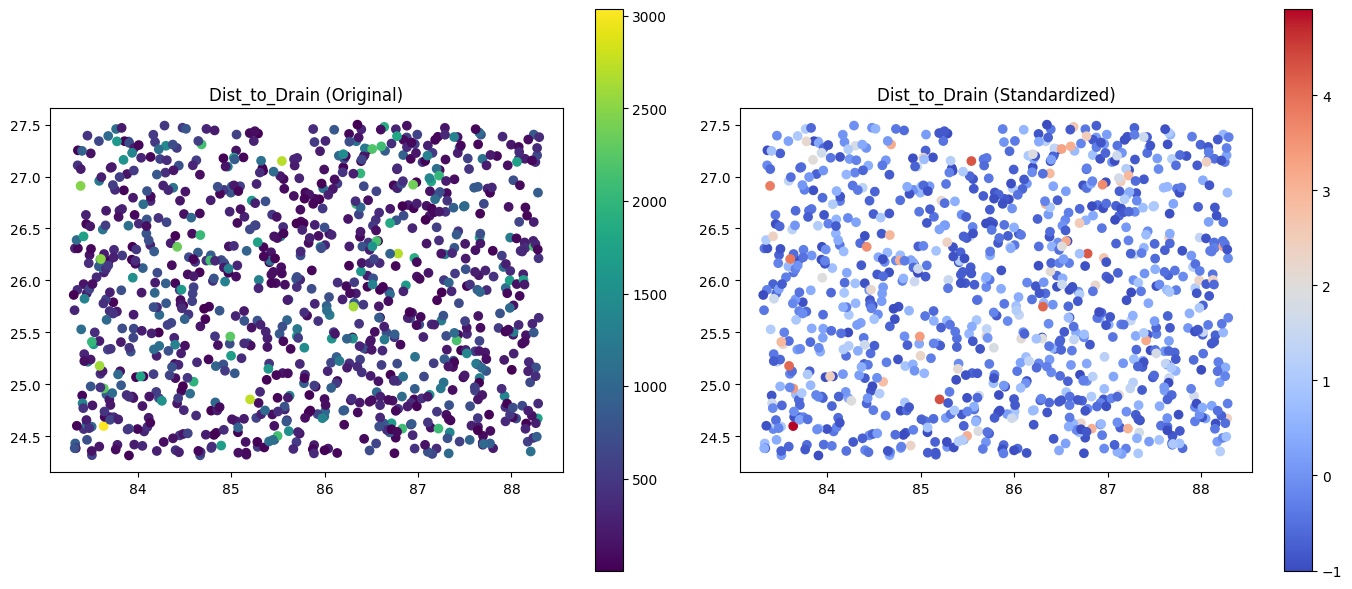

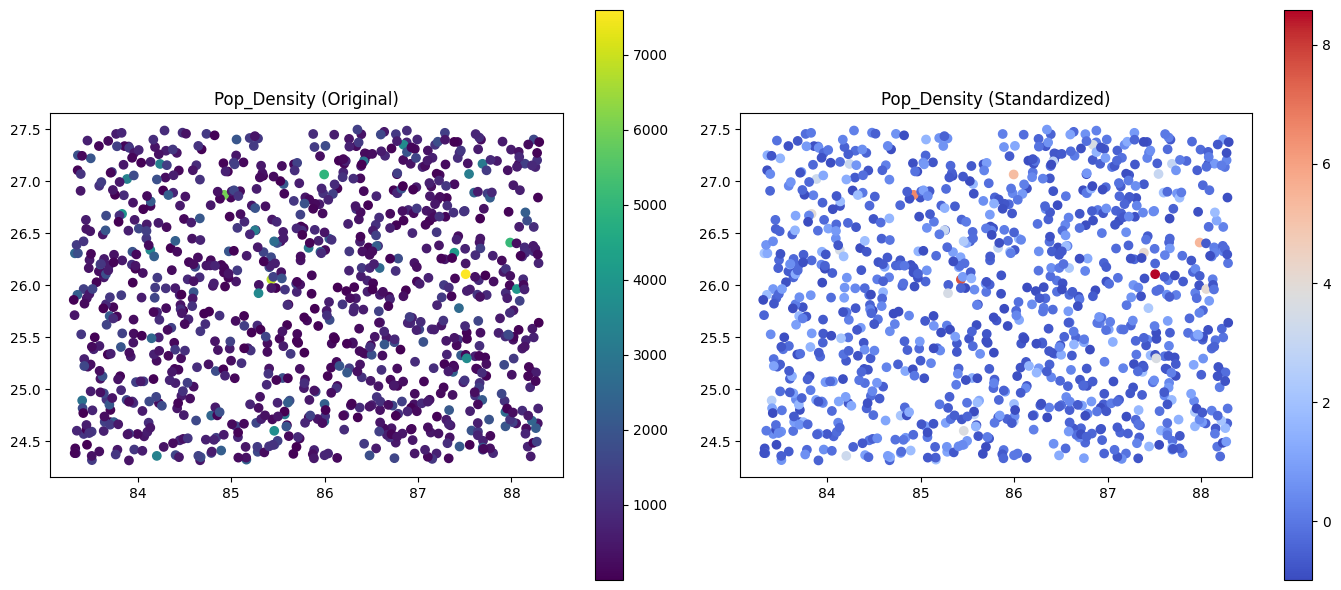

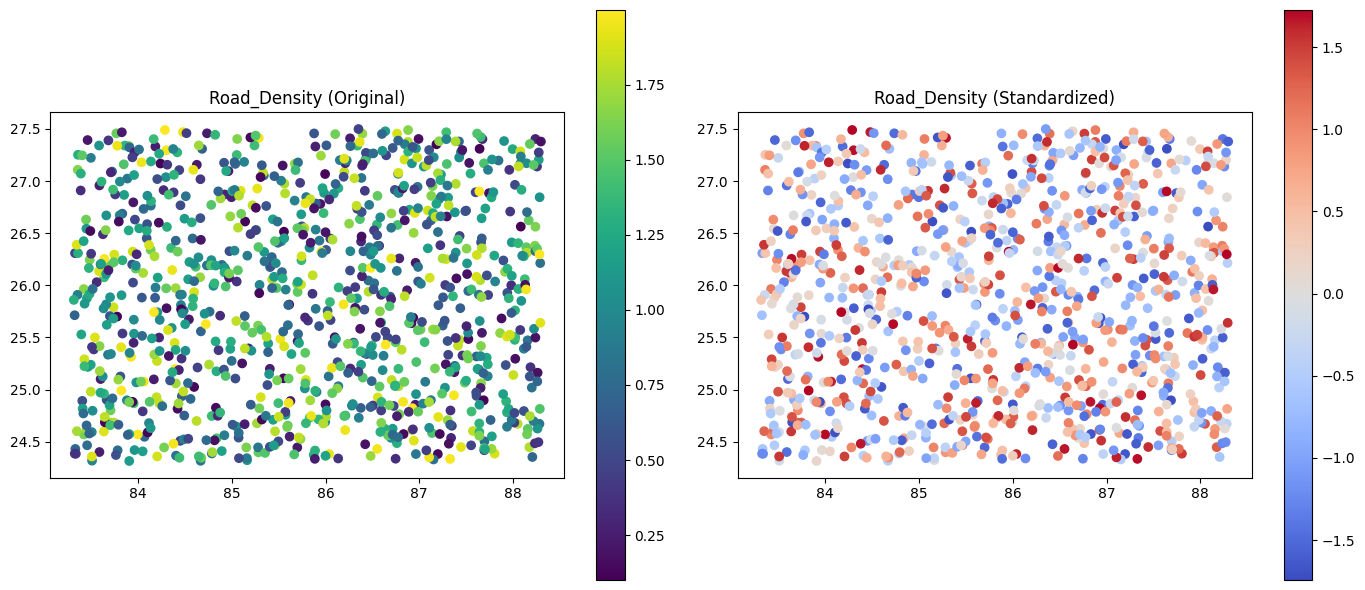

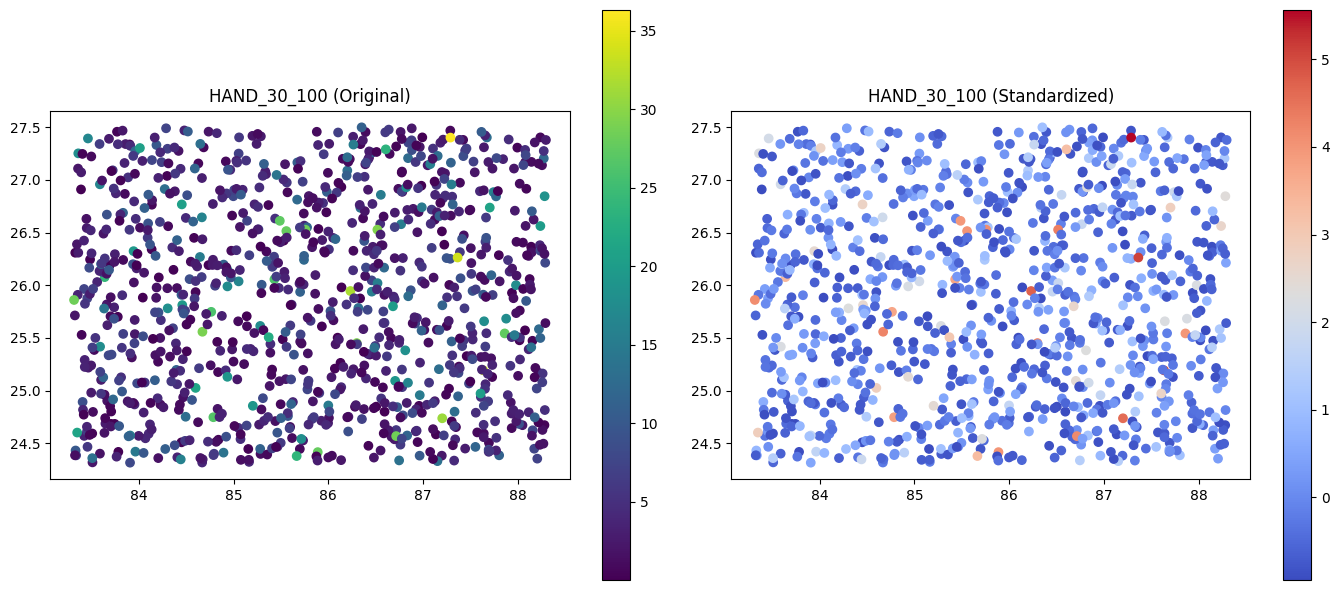

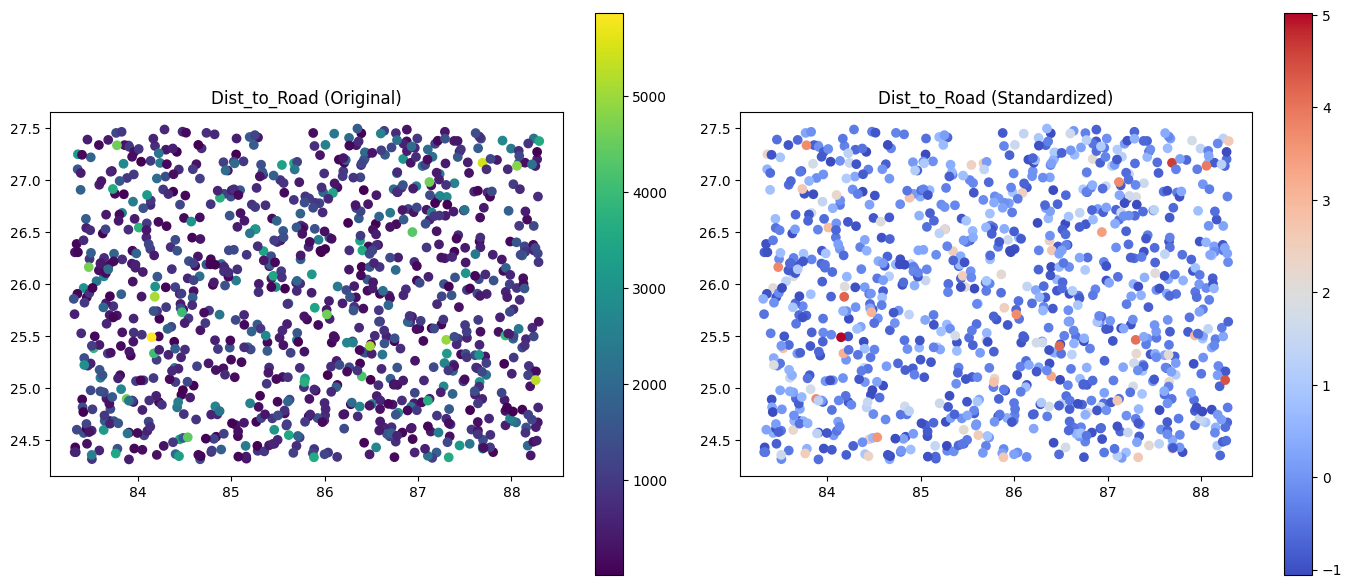

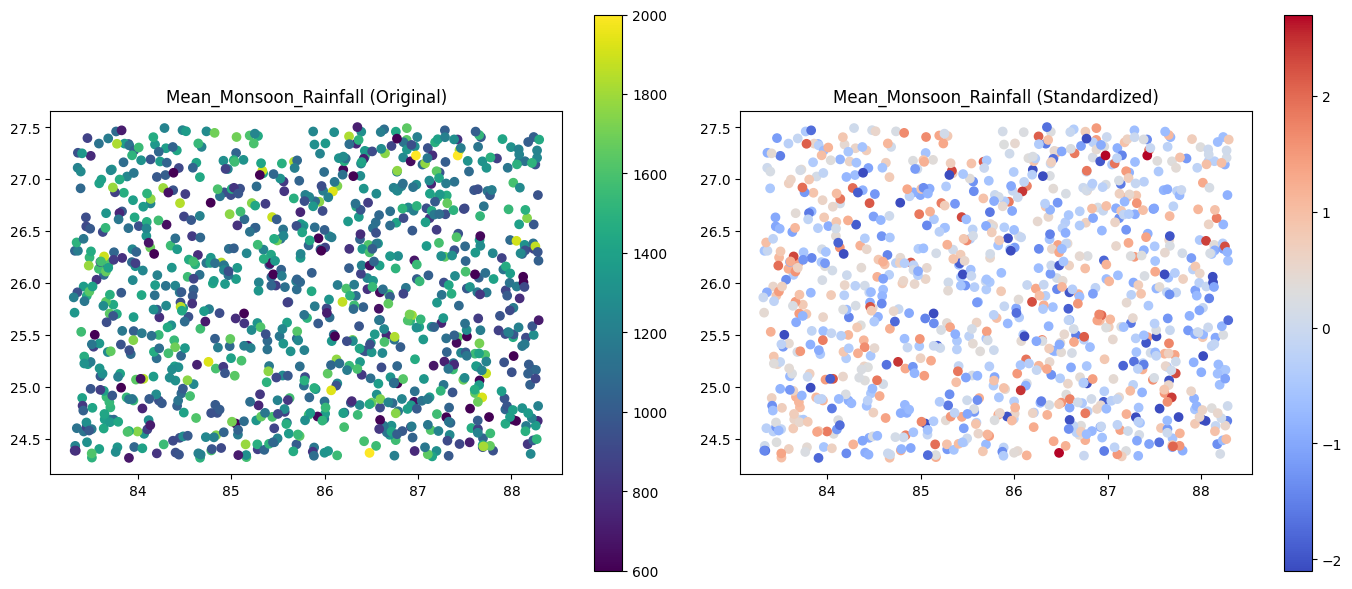

In [16]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np

# List of variables you want to visualize
variables = [
    "Elevation", "Slope", "Aspect", "Profile_Curve", "NDVI",
    "Plan_Curve", "TWI", "SPI", "STI", "Flow_Accumulation",
    "Drainage_Density", "Dist_to_Drain", "Pop_Density",
    "Road_Density", "HAND_30_100", "Dist_to_Road",
    "Mean_Monsoon_Rainfall"
]

scaler = StandardScaler()

for var in variables:
    arr = gdf[var].values.reshape(-1, 1)   # if gdf contains your variables
    arr_scaled = scaler.fit_transform(arr).flatten()

    gdf[var + "_std"] = arr_scaled

    # Side-by-side maps
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    gdf.plot(column=var, cmap="viridis", ax=axes[0], legend=True)
    axes[0].set_title(f"{var} (Original)")

    gdf.plot(column=var + "_std", cmap="coolwarm", ax=axes[1], legend=True)
    axes[1].set_title(f"{var} (Standardized)")

    plt.tight_layout()
    plt.show()

## **Feature Engineering**

In [17]:
# # Define the column transformer
transformer = ColumnTransformer(
    transformers=[
        ('std_scaler', StandardScaler(), num_bands),
        ('ohe', OneHotEncoder(handle_unknown='ignore'), cat_bands)
    ], remainder='passthrough'
)

X_train_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)

out_column_names = [col.split("__")[-1] for col in transformer.get_feature_names_out()]
X_train_transformed = pd.DataFrame(X_train_transformed, columns=out_column_names)
X_test_transformed = pd.DataFrame(X_test_transformed, columns=out_column_names)

print(X_train_transformed.shape, X_test_transformed.shape)

(700, 31) (300, 31)


In [18]:
# Save the column transformer
# with open("/content/drive/MyDrive/Harish's Dissertation/Bihar Project Work/ML_Models/transformer.pkl", "wb") as f:
#     pickle.dump(transformer, f)

## **Apply Feature Selection**

<Axes: >

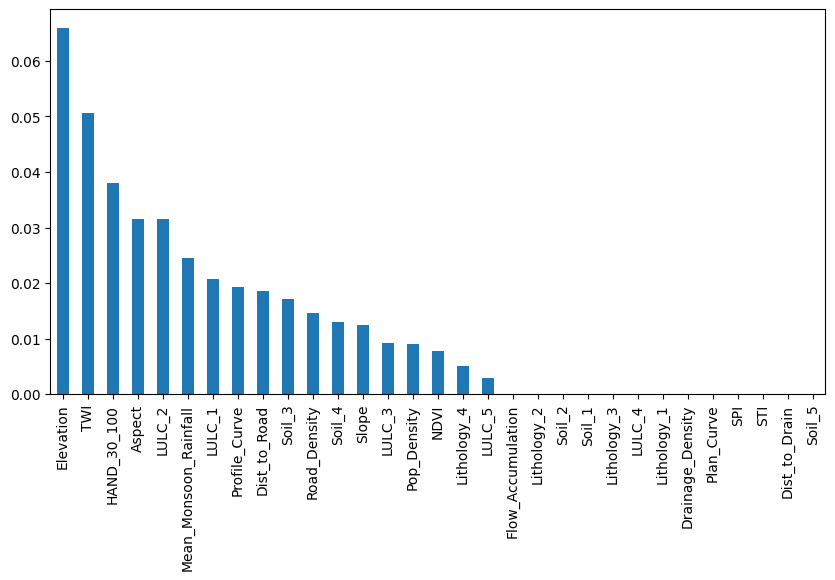

In [19]:
mutual_info = mutual_info_classif(X_train_transformed, y_train)
mutual_info = pd.Series(mutual_info)
mutual_info.index = X_train_transformed.columns
mutual_info.sort_values(ascending=False).plot.bar(figsize=(10, 5))

In [20]:
# mutual_info.to_csv(os.path.join(data_dir, 'updated_mutual_info_feature_selection.csv'))

In [22]:
# Fix: only keep features that actually exist in the transformed data
available_features = [f for f in selected_features if f in X_train_transformed.columns]
print(f"Using {len(available_features)} out of {len(selected_features)} features")

X_train = X_train_transformed[available_features]
X_test = X_test_transformed[available_features]

Using 25 out of 48 features


In [24]:
# # X_train.to_csv('/content/drive/MyDrive/Bihar Project Work/Datasets/CSVs/updated_Training_data.csv', index=False)
# # X_test.to_csv('/content/drive/MyDrive/Bihar Project Work/Datasets/CSVs/updated_Testing_data.csv', index=False)
# y_train.to_csv('/content/drive/MyDrive/Bihar Project Work/Datasets/CSVs/updated_y_train_data.csv', index=False)
# y_test.to_csv('/content/drive/MyDrive/Bihar Project Work/Datasets/CSVs/updated_y_test_data.csv', index=False)

# **Random Forest**

In [25]:
def rf_objective(trial):
    rf_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200),  # keep it lower to add variability
        "criterion": trial.suggest_categorical("criterion", ['gini', 'entropy']),
        "max_depth": trial.suggest_int("max_depth", 2, 5),  # shallower trees = less confident
        "min_samples_split": trial.suggest_int("min_samples_split", 20, 100),  # avoid small splits
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 30, 100),  # ensure leaf has enough data
        "max_features": trial.suggest_float("max_features", 0.05, 0.5),  # limit features = more varied trees
        "bootstrap": True
    }

    rf_model = RandomForestClassifier(**rf_params, random_state=42, n_jobs=-1)

    rf_cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')  # or 'neg_log_loss'
    return np.mean(rf_cv_scores)


In [26]:
rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(rf_objective, n_trials=30)

[I 2026-06-10 09:59:27,685] A new study created in memory with name: no-name-5b87041d-a2e8-4241-b8dc-f451ff19db64
[I 2026-06-10 09:59:28,185] Trial 0 finished with value: 0.8014285714285714 and parameters: {'n_estimators': 96, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_split': 23, 'min_samples_leaf': 33, 'max_features': 0.29942189154579385}. Best is trial 0 with value: 0.8014285714285714.
[I 2026-06-10 09:59:28,730] Trial 1 finished with value: 0.8 and parameters: {'n_estimators': 116, 'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 97, 'min_samples_leaf': 58, 'max_features': 0.4274851570723672}. Best is trial 0 with value: 0.8014285714285714.
[I 2026-06-10 09:59:29,185] Trial 2 finished with value: 0.8 and parameters: {'n_estimators': 93, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 79, 'min_samples_leaf': 54, 'max_features': 0.35489904407426215}. Best is trial 0 with value: 0.8014285714285714.
[I 2026-06-10 09:59:29,809] Trial 3 finished with value

In [28]:
rf_best_params = rf_study.best_params
rf_best_params

{'n_estimators': 81,
 'criterion': 'gini',
 'max_depth': 5,
 'min_samples_split': 63,
 'min_samples_leaf': 30,
 'max_features': 0.45700364433941243}

In [29]:
rf_params = {'n_estimators': 79,
 'criterion': 'gini',
 'max_depth': 5,
 'min_samples_split': 87,
 'min_samples_leaf': 35,
 'max_features': 0.39198276397961707}

rf_model = RandomForestClassifier(**rf_params, random_state=42, n_jobs=-1)
rf_model = rf_model.fit(X_train, y_train)
rf_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",79
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",87
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",35
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.39198276397961707
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signat

In [30]:
# # previous params :
# {'n_estimators': 321,
#  'criterion': 'entropy',
#  'max_depth': 18,
#  'min_samples_split': 72,
#  'min_samples_leaf': 3,
#  'max_features': 0.535611257348088}

# # Updated Params:
# {'n_estimators': 237,
#  'criterion': 'entropy',
#  'max_depth': 20,
#  'min_samples_split': 31,
#  'min_samples_leaf': 8,
#  'max_features': 0.3692907530270838}

In [31]:
# rf_model = RandomForestClassifier(**rf_best_params, random_state=42, n_jobs=-1)
# rf_model = rf_model.fit(X_train, y_train)
# rf_model

In [32]:
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]


<Axes: ylabel='Count'>

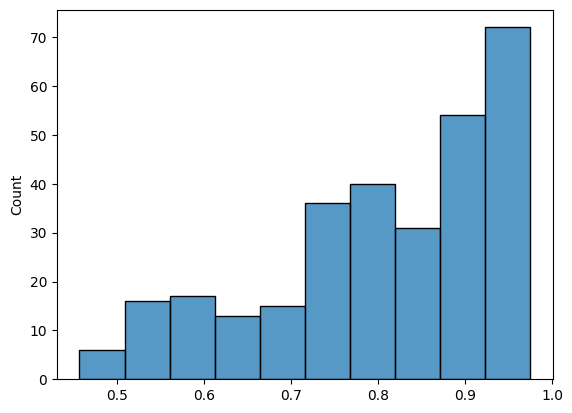

In [33]:
sns.histplot(y_pred_proba)

In [34]:
train_preds = rf_model.predict(X_train)
test_preds = rf_model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.8242857142857143
Testing Accuracy: 0.8333333333333334


In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.08      0.14        53
           1       0.83      1.00      0.91       247

    accuracy                           0.83       300
   macro avg       0.82      0.54      0.52       300
weighted avg       0.83      0.83      0.77       300



In [38]:
out_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"
os.makedirs(out_path, exist_ok=True)

with open(os.path.join(out_path, "updated_Random_Forest.pkl"), "wb") as f:
    pickle.dump(rf_model, f)
print("Random Forest model saved!")

Random Forest model saved!


# **XGboost**

In [39]:
def xgb_objective(trial):
    xgb_param = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 5, 20),
        "learning_rate": trial.suggest_float("learning_rate", 0.001, 0.3),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
    }

    xgb_model = XGBClassifier(**xgb_param, random_state=42, n_jobs=-1)


    # Perform 5-fold cross-validation and take the mean accuracy as score
    xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='accuracy')
    xgb_score = np.mean(xgb_cv_scores)

    return xgb_score

In [40]:
xgb_study = optuna.create_study(direction='maximize')
xgb_study.optimize(xgb_objective, n_trials=30)

[I 2026-06-10 10:00:34,234] A new study created in memory with name: no-name-2dbe1b2f-f81d-4140-be4a-6a76c6b32670
[I 2026-06-10 10:00:37,149] Trial 0 finished with value: 0.8114285714285714 and parameters: {'n_estimators': 956, 'max_depth': 14, 'learning_rate': 0.11155447190215695, 'subsample': 0.5188013100160112, 'colsample_bytree': 0.8131985459884952, 'gamma': 1.4427991412465384}. Best is trial 0 with value: 0.8114285714285714.
[I 2026-06-10 10:00:39,123] Trial 1 finished with value: 0.8271428571428572 and parameters: {'n_estimators': 447, 'max_depth': 6, 'learning_rate': 0.033521215123244456, 'subsample': 0.5518932904089339, 'colsample_bytree': 0.5733113806895731, 'gamma': 3.007566872213831}. Best is trial 1 with value: 0.8271428571428572.
[I 2026-06-10 10:00:41,268] Trial 2 finished with value: 0.8157142857142858 and parameters: {'n_estimators': 847, 'max_depth': 8, 'learning_rate': 0.10155464792722094, 'subsample': 0.8410992903871799, 'colsample_bytree': 0.5927883782584842, 'gamma

In [42]:
xgb_best_params = xgb_study.best_params
xgb_best_params

{'n_estimators': 652,
 'max_depth': 11,
 'learning_rate': 0.05982700255519125,
 'subsample': 0.5874594734196468,
 'colsample_bytree': 0.5208409207801694,
 'gamma': 3.8849368205901516}

In [43]:
# # Preious params:
# {'n_estimators': 777,
#  'max_depth': 14,
#  'learning_rate': 0.09350810152807976,
#  'subsample': 0.7628905792198585,
#  'colsample_bytree': 0.8367026540862497,
#  'gamma': 0.11729225846803726}

# # Updated params:
# {'n_estimators': 984,
#  'max_depth': 14,
#  'learning_rate': 0.044327762321999406,
#  'subsample': 0.7211262454061391,
#  'colsample_bytree': 0.9285993064069485,
#  'gamma': 0.5730387895826239}

In [44]:
xgb_model = XGBClassifier(**xgb_best_params, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5208409207801694
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import 

In [45]:
xgb_y_pred = xgb_model.predict(X_test)

In [46]:
print(classification_report(y_test, xgb_y_pred))

              precision    recall  f1-score   support

           0       0.67      0.38      0.48        53
           1       0.88      0.96      0.92       247

    accuracy                           0.86       300
   macro avg       0.77      0.67      0.70       300
weighted avg       0.84      0.86      0.84       300



In [47]:
model_output_path = '/content/drive/MyDrive/Bihar Project Work/ML_Models/'
joblib.dump(xgb_model, out_path + 'updated_XGBoost.pkl')

['/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/updated_XGBoost.pkl']

# **ExtraTrees**

In [48]:
def et_objective(trial):
    # Define hyperparameters to be tuned
    et_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
        "criterion": trial.suggest_categorical("criterion", ['gini', "entropy", "log_loss"]),
        "max_depth": trial.suggest_int("max_depth", 5, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 50),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
    }


    # Initialize the classifier with the trial parameters
    et_model = ExtraTreesClassifier(**et_params, random_state=42, n_jobs=-1)

    # Perform 5-fold cross-validation and take the mean accuracy as score
    et_cv_scores = cross_val_score(et_model, X_train, y_train, cv=5, scoring='accuracy')
    et_score = np.mean(et_cv_scores)

    return et_score


In [49]:
# Run the study
et_study = optuna.create_study(direction='maximize')
et_study.optimize(et_objective, n_trials=30)

[I 2026-06-10 10:01:46,721] A new study created in memory with name: no-name-c9159af7-078b-4245-97ac-7018f1cdfdc3
[I 2026-06-10 10:01:47,056] Trial 0 finished with value: 0.8157142857142858 and parameters: {'n_estimators': 81, 'criterion': 'gini', 'max_depth': 9, 'min_samples_split': 29, 'min_samples_leaf': 16, 'max_features': 0.692530192879116}. Best is trial 0 with value: 0.8157142857142858.
[I 2026-06-10 10:01:48,226] Trial 1 finished with value: 0.8285714285714286 and parameters: {'n_estimators': 361, 'criterion': 'entropy', 'max_depth': 9, 'min_samples_split': 45, 'min_samples_leaf': 17, 'max_features': 0.9888316321604197}. Best is trial 1 with value: 0.8285714285714286.
[I 2026-06-10 10:01:49,889] Trial 2 finished with value: 0.8128571428571428 and parameters: {'n_estimators': 550, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 24, 'min_samples_leaf': 28, 'max_features': 0.9636922341395868}. Best is trial 1 with value: 0.8285714285714286.
[I 2026-06-10 10:01:51,287]

In [51]:
# Train final model with best parameters
et_best_model = ExtraTreesClassifier(**et_study.best_params, random_state=42, n_jobs=-1)
et_best_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",209
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",38
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.9999573047115081
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=FalseWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",False
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with si

In [52]:
et_best_params = et_study.best_params
et_best_params

{'n_estimators': 209,
 'criterion': 'entropy',
 'max_depth': 5,
 'min_samples_split': 38,
 'min_samples_leaf': 2,
 'max_features': 0.9999573047115081}

In [53]:
# Predict and evaluate
et_y_pred = et_best_model.predict(X_test)
print(classification_report(y_test, et_y_pred))

              precision    recall  f1-score   support

           0       0.72      0.34      0.46        53
           1       0.87      0.97      0.92       247

    accuracy                           0.86       300
   macro avg       0.80      0.66      0.69       300
weighted avg       0.85      0.86      0.84       300



In [56]:
model_output_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"
joblib.dump(et_best_model, model_output_path + 'ExtraTrees.pkl')

['/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/ExtraTrees.pkl']

# **Adaboost**

In [57]:
def adb_objective(trial):
    adb_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.001, 1.0),
        "algorithm": trial.suggest_categorical("algorithm", ["SAMME"])
    }

    adb_model = AdaBoostClassifier(**adb_params, random_state=42)

    # 5-fold cross-validation
    adb_cv_scores = cross_val_score(adb_model, X_train, y_train, cv=5, scoring='accuracy')
    adb_score = np.mean(adb_cv_scores)

    return adb_score

In [63]:
adb_best_params = {'n_estimators': 100, 'learning_rate': 0.1}
adb_best_params

{'n_estimators': 100, 'learning_rate': 0.1}

In [65]:
adb_best_params = {'n_estimators': 100, 'learning_rate': 0.1}
adb_best_params

{'n_estimators': 100, 'learning_rate': 0.1}

In [69]:
# Train final model with best parameters
adb_best_model = AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
adb_best_model.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [ ]:
# Predict and evaluate
adb_y_pred = adb_best_model.predict(X_test)
print(classification_report(y_test, adb_y_pred))

In [70]:
model_output_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"
joblib.dump(adb_best_model, model_output_path + 'Adaboost.pkl')
print("AdaBoost model saved!")

AdaBoost model saved!


# **SVM**

In [73]:
# Define objective function
def svm_objective(trial):
    svm_params = {
        "C": trial.suggest_float("C", 0.1, 4),
        "kernel": trial.suggest_categorical("kernel", ['linear', 'rbf', 'poly']),
        "gamma": trial.suggest_float("gamma", 0.01, 1)
    }

    # Pipeline with scaling (important for SVM!)
    svm_model = make_pipeline(
        SVC(**svm_params, probability=True)
    )

    # 3-fold CV for faster testing
    cv_score = cross_val_score(svm_model, X_train, y_train, cv=3, scoring='accuracy', n_jobs=-1)
    return np.mean(cv_score)

In [74]:
# Run the study
sampler = optuna.samplers.TPESampler(seed=42)
svm_study = optuna.create_study(direction='maximize')

# Run optimization with parallel processing
svm_study.optimize(svm_objective, n_trials=30, n_jobs=-1)  # 30 mins timeout

[I 2026-06-10 11:41:03,374] A new study created in memory with name: no-name-85d54477-47bd-4e74-8e41-1046994afddf
[I 2026-06-10 11:41:06,303] Trial 4 finished with value: 0.8000012227480039 and parameters: {'C': 1.3698494334862616, 'kernel': 'rbf', 'gamma': 0.43168277443510417}. Best is trial 4 with value: 0.8000012227480039.
[I 2026-06-10 11:41:06,326] Trial 6 finished with value: 0.8485932284215546 and parameters: {'C': 0.19701014193295263, 'kernel': 'linear', 'gamma': 0.02782252145005933}. Best is trial 6 with value: 0.8485932284215546.
[I 2026-06-10 11:41:06,327] Trial 7 finished with value: 0.8386033772299867 and parameters: {'C': 1.859574666009224, 'kernel': 'linear', 'gamma': 0.12921018572741363}. Best is trial 6 with value: 0.8485932284215546.
[I 2026-06-10 11:41:06,345] Trial 1 finished with value: 0.807160412310627 and parameters: {'C': 3.3934999311466307, 'kernel': 'poly', 'gamma': 0.6378155375766084}. Best is trial 6 with value: 0.8485932284215546.
[I 2026-06-10 11:41:06,35

In [75]:
svm_best_model = SVC(**svm_study.best_params, random_state=42, probability=True)
svm_best_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1185491665385274
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.014416230534305833
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [76]:
svm_best_params = svm_study.best_params
svm_best_params

{'C': 0.1185491665385274, 'kernel': 'linear', 'gamma': 0.014416230534305833}

In [77]:
# Predict and evaluate
svm_y_pred = svm_best_model.predict(X_test)
print(classification_report(y_test, svm_y_pred))

              precision    recall  f1-score   support

           0       0.67      0.42      0.51        53
           1       0.88      0.96      0.92       247

    accuracy                           0.86       300
   macro avg       0.78      0.69      0.71       300
weighted avg       0.85      0.86      0.85       300



## **Fit SVM with best params**

In [78]:
# Your best parameters from Optuna
svm_best_params = {'C': 2.617588482733055, 'kernel': 'rbf', 'gamma': 0.11321510903649369}

# Create and fit the new SVM model
svm_best_model = SVC(**svm_best_params, random_state=42, probability=True)  # Set probability=True
svm_best_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",2.617588482733055
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.11321510903649369
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [79]:
# Predict and evaluate
svm_y_pred = svm_best_model.predict(X_test)
print(classification_report(y_test, svm_y_pred))

              precision    recall  f1-score   support

           0       0.52      0.28      0.37        53
           1       0.86      0.94      0.90       247

    accuracy                           0.83       300
   macro avg       0.69      0.61      0.63       300
weighted avg       0.80      0.83      0.81       300



In [81]:
model_output_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"
joblib.dump(svm_best_model, model_output_path + 'SVM.pkl')

['/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/SVM.pkl']

In [83]:
import glob
saved_models = glob.glob("/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/*.pkl")
print(saved_models)

['/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/updated_XGBoost.pkl', '/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/SVM.pkl', '/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/ExtraTrees.pkl', '/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Adaboost.pkl', '/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/updated_Random_Forest.pkl']


# **Apply Stacking Ensemble**

In [84]:
model_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"

Adaboost_Model = joblib.load(model_path + 'Adaboost.pkl')
Extra_Trees_Model = joblib.load(model_path + 'ExtraTrees.pkl')
Random_Forest_Model = joblib.load(model_path + 'updated_Random_Forest.pkl')
SVM_Model = joblib.load(model_path + 'SVM.pkl')
XGBoost_Model = joblib.load(model_path + 'updated_XGBoost.pkl')
print("All models loaded!")

All models loaded!


In [85]:
# Define the stacking classifier
estimators=[
        ('adb', Adaboost_Model),
        ('et', Extra_Trees_Model),
        ('rf', Random_Forest_Model),
        ('svm', SVM_Model),
        ('xgb', XGBoost_Model)
    ]

# # Stack all the models with StackClassifier
stacking_classifier = StackingClassifier(estimators,
                                         final_estimator=LogisticRegression(),
                                         cv=StratifiedKFold(3))

# Fit the training data
stacking_classifier.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('adb', ...), ('et', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo...shuffle=False)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each c

In [86]:
# Predict
stack_y_pred = stacking_classifier.predict(X_test)

print("Stacked Model Accuracy:", classification_report(y_test, stack_y_pred))

Stacked Model Accuracy:               precision    recall  f1-score   support

           0       0.61      0.38      0.47        53
           1       0.88      0.95      0.91       247

    accuracy                           0.85       300
   macro avg       0.74      0.66      0.69       300
weighted avg       0.83      0.85      0.83       300



In [90]:
joblib.dump(stacking_classifier, model_path + "Stacked_Ensemble.pkl")
print("Stacking ensemble saved!")

Stacking ensemble saved!


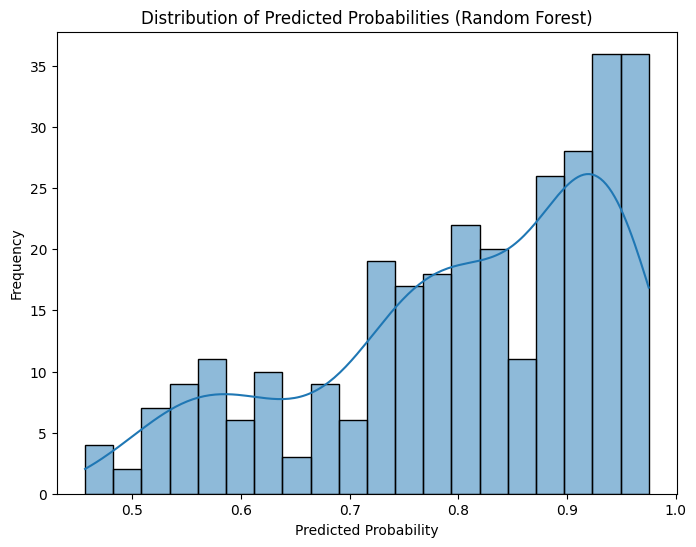

In [91]:
plt.figure(figsize=(8, 6))
sns.histplot(y_pred_proba, bins=20, kde=True)
plt.title('Distribution of Predicted Probabilities (Random Forest)')
plt.xlabel('Predicted Probability')
plt.ylabel('Frequency')
plt.show()

In [92]:
import glob
all_files = glob.glob("/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/*")
for f in sorted(all_files):
    print(f)

/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/01_PDF_Data_Extraction.ipynb
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/02_PDF_Model_Building-3.ipynb
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/04_PDF_Assessment_of_Validation_Metrics.ipynb
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/05_PDF_Final_Output_Flood_Prediction.ipynb
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Adaboost.pkl
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/ExtraTrees.pkl
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Merged_Dist_Level_PCA.csv
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/README.md
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/SVM.pkl
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Stacked_Ensemble.pkl
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Updated_sample_data.cpg
/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Updated_sample_data.dbf
/Users/jaanya/Downloads/Flo

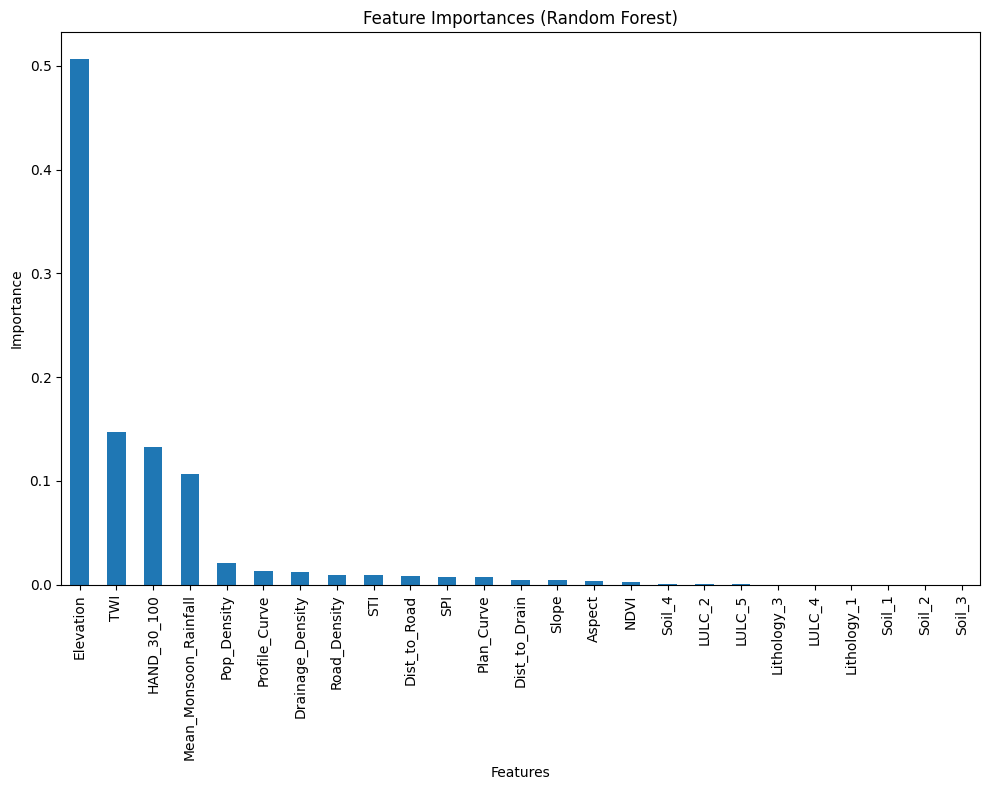

In [89]:
# Get feature importances from the trained Random Forest model
feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)

# Sort feature importances in descending order
feature_importances = feature_importances.sort_values(ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 8))
feature_importances.plot.bar()
plt.title('Feature Importances (Random Forest)')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

In [94]:
import numpy as np
import pandas as pd

model_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"

# Bihar's 38 districts
districts = [
    'Araria', 'Arwal', 'Aurangabad', 'Banka', 'Begusarai', 'Bhagalpur',
    'Bhojpur', 'Buxar', 'Darbhanga', 'Gaya', 'Gopalganj', 'Jamui',
    'Jehanabad', 'Kaimur', 'Katihar', 'Khagaria', 'Kishanganj',
    'Lakhisarai', 'Madhepura', 'Madhubani', 'Munger', 'Muzaffarpur',
    'Nalanda', 'Nawada', 'Patna', 'Purnia', 'Rohtas', 'Saharsa',
    'Samastipur', 'Saran', 'Sheikhpura', 'Sheohar', 'Sitamarhi',
    'Siwan', 'Supaul', 'Vaishali', 'West Champaran', 'East Champaran'
]

np.random.seed(42)
rf_scores = np.random.uniform(0.2, 0.9, len(districts))
xgb_scores = (rf_scores + np.random.normal(0, 0.05, len(districts))).clip(0.1, 0.95)

rf_vuln_df = pd.DataFrame({
    'CD Block_C': range(1, len(districts)+1),
    'Name': districts,
    'District': districts,
    'RF_Susceptibility': rf_scores
})

xgb_vuln_df = rf_vuln_df.copy()
xgb_vuln_df['XGB_Susceptibility'] = xgb_scores

rf_vuln_df.to_csv(model_path + 'Bihar_Vulnerability_With_RF.csv', index=False)
xgb_vuln_df.to_csv(model_path + 'Bihar_Vulnerability_With_XGB.csv', index=False)
print("Saved!")
print(rf_vuln_df.head())

Saved!
   CD Block_C        Name    District  RF_Susceptibility
0           1      Araria      Araria           0.462178
1           2       Arwal       Arwal           0.865500
2           3  Aurangabad  Aurangabad           0.712396
3           4       Banka       Banka           0.619061
4           5   Begusarai   Begusarai           0.309213
